In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [60]:
var = 1
x = np.random.normal(0, var, size=(1000, 1))
y = np.random.normal(0, var, size=(1000, 1))
feats = np.column_stack((x, y))

z = x + y + np.random.normal(0, 0.1, size=(1000, 1))

base_model = LinearRegression()
base_model.fit(feats, z)

residuals = (base_model.predict(feats) - z)**2

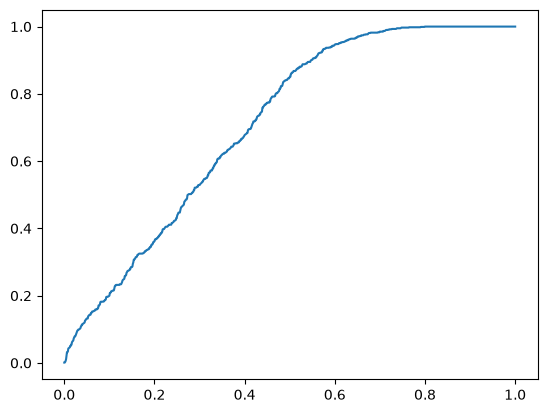

In [104]:
# z is faulty
pvals = []
for i in range(1000):
    x = np.random.normal(0, var)
    y = np.random.normal(0, var)

    z = x + np.random.normal(1, 0.3) * y + np.random.normal(0, 0.1)

    z_pred = base_model.predict([[x, y]])

    residual = (z_pred - z) ** 2
    pvals.append(np.mean(residual > residuals)) # how often is our residual bigger than the other residuals

pvals = np.array(pvals)
pvals.sort()

plt.plot(np.linspace(0, 1, num=len(pvals)), pvals)

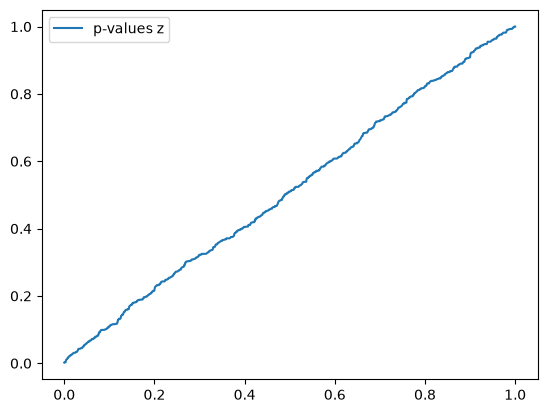

In [95]:
# x is faulty
pvals_z = []
for i in range(1000):
    x = np.random.normal(1, var)
    y = np.random.normal(0, var)

    z = x + y + np.random.normal(0, 0.1)

    z_pred = base_model.predict([[x, y]])

    residual = (z_pred - z) ** 2
    pvals_z.append(np.mean(residual > residuals)) # how often is our residual bigger than the other residuals

pvals_z = np.array(pvals_z)
pvals_z.sort()

plt.plot(np.linspace(0, 1, num=len(pvals_z)), pvals_z, label="p-values z")
plt.legend()